# BharatMarket AI
## Notebook 03: Data Preprocessing and Feature Engineering

### Objective
Prepare historical market datasets for statistical and machine
learning forecasting models.

### Major Components
1. Data cleaning
2. Missing value treatment
3. Return calculation
4. Moving averages
5. Momentum indicators
6. Volatility indicators
7. Volume indicators
8. Lag features
9. Calendar features
10. Forecasting target generation

### Instruments
NIFTY 50, BANK NIFTY and eight NSE-listed stocks.

### Prediction Objective
Forecast the next trading session's closing price and return.

In [1]:
# ============================================
# CELL 1: IMPORT LIBRARIES
# ============================================

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (14, 6)

print("BharatMarket AI")
print("Data Preprocessing and Feature Engineering")
print("Libraries imported successfully!")

BharatMarket AI
Data Preprocessing and Feature Engineering
Libraries imported successfully!


In [2]:
# ============================================
# CELL 2: PROJECT CONFIGURATION
# ============================================

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"

FEATURE_DATA_DIR = (
    PROJECT_DIR / "data" / "features"
)

OUTPUT_DIR = PROJECT_DIR / "outputs"

CHART_DIR = OUTPUT_DIR / "charts"
REPORT_DIR = OUTPUT_DIR / "reports"

for folder in [
    FEATURE_DATA_DIR,
    CHART_DIR,
    REPORT_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

INSTRUMENTS = {
    "NIFTY50": "NIFTY 50",
    "BANKNIFTY": "BANK NIFTY",
    "RELIANCE": "Reliance Industries",
    "TCS": "Tata Consultancy Services",
    "HDFCBANK": "HDFC Bank",
    "INFY": "Infosys",
    "ICICIBANK": "ICICI Bank",
    "SBIN": "State Bank of India",
    "ITC": "ITC Limited",
    "LT": "Larsen & Toubro"
}

print("Project configured successfully!")

Project configured successfully!


In [3]:
# ============================================
# CELL 3: LOAD PROCESSED DATASETS
# ============================================

market_data = {}

for symbol, company in INSTRUMENTS.items():

    file_path = (
        PROCESSED_DATA_DIR /
        f"{symbol}_processed.csv"
    )

    if not file_path.exists():
        print("Missing dataset:", symbol)
        continue

    df = pd.read_csv(file_path)

    df["date"] = pd.to_datetime(df["date"])

    df = df.sort_values("date").reset_index(drop=True)

    market_data[symbol] = df

    print(f"{symbol}: {len(df)} rows loaded")

print("\nTotal datasets:", len(market_data))

assert len(market_data) == 10, (
    "Not all datasets were loaded. Check Notebook 01."
)

NIFTY50: 1236 rows loaded
BANKNIFTY: 1235 rows loaded
RELIANCE: 1237 rows loaded
TCS: 1237 rows loaded
HDFCBANK: 1237 rows loaded
INFY: 1237 rows loaded
ICICIBANK: 1237 rows loaded
SBIN: 1237 rows loaded
ITC: 1237 rows loaded
LT: 1237 rows loaded

Total datasets: 10


In [4]:
# ============================================
# CELL 4: DATA CLEANING
# ============================================

cleaned_data = {}

cleaning_results = []

for symbol, df in market_data.items():

    original_rows = len(df)

    df = df.copy()

    # Remove duplicate dates
    df = df.drop_duplicates(
        subset="date",
        keep="last"
    )

    # Remove invalid dates
    df = df.dropna(subset=["date"])

    # Remove records without essential OHLC values
    required = ["open", "high", "low", "close"]

    df = df.dropna(subset=required)

    # Remove non-positive prices
    df = df[
        (df[required] > 0).all(axis=1)
    ]

    # Validate OHLC relationships
    valid_ohlc = (
        (df["high"] >= df["low"]) &
        (df["high"] >= df["open"]) &
        (df["high"] >= df["close"]) &
        (df["low"] <= df["open"]) &
        (df["low"] <= df["close"])
    )

    df = df[valid_ohlc]

    # Remove negative volume records
    df = df[df["volume"] >= 0]

    df = df.sort_values("date").reset_index(drop=True)

    cleaned_data[symbol] = df

    cleaning_results.append({
        "Symbol": symbol,
        "Original Rows": original_rows,
        "Cleaned Rows": len(df),
        "Rows Removed": original_rows - len(df)
    })

cleaning_df = pd.DataFrame(cleaning_results)

display(cleaning_df)

cleaning_df.to_csv(
    REPORT_DIR / "feature_data_cleaning_report.csv",
    index=False
)

print("Data cleaning completed.")

,Symbol,Original Rows,Cleaned Rows,Rows Removed
0,NIFTY50,1236,1236,0
1,BANKNIFTY,1235,1235,0
2,RELIANCE,1237,1237,0
3,TCS,1237,1237,0
4,HDFCBANK,1237,1237,0
5,INFY,1237,1237,0
6,ICICIBANK,1237,1237,0
7,SBIN,1237,1237,0
8,ITC,1237,1237,0
9,LT,1237,1237,0


Data cleaning completed.


In [5]:
# ============================================
# CELL 5: RETURN FEATURES
# ============================================

for symbol, df in cleaned_data.items():

    df["daily_return"] = (
        df["close"].pct_change(fill_method=None) * 100
    )

    df["weekly_return"] = (
        df["close"].pct_change(
            periods=5,
            fill_method=None
        ) * 100
    )

    df["monthly_return"] = (
        df["close"].pct_change(
            periods=21,
            fill_method=None
        ) * 100
    )

    cleaned_data[symbol] = df

print("Daily, weekly and monthly returns calculated.")

Daily, weekly and monthly returns calculated.


In [6]:
# ============================================
# CELL 6: SIMPLE MOVING AVERAGES
# ============================================

SMA_PERIODS = [5, 10, 20, 50, 100, 200]

for symbol, df in cleaned_data.items():

    for period in SMA_PERIODS:

        df[f"sma_{period}"] = (
            df["close"]
            .rolling(window=period)
            .mean()
        )

    cleaned_data[symbol] = df

print("SMA features generated successfully.")

SMA features generated successfully.


In [7]:
# ============================================
# CELL 7: EXPONENTIAL MOVING AVERAGES
# ============================================

EMA_PERIODS = [9, 12, 20, 26, 50]

for symbol, df in cleaned_data.items():

    for period in EMA_PERIODS:

        df[f"ema_{period}"] = (
            df["close"]
            .ewm(
                span=period,
                adjust=False,
                min_periods=period
            )
            .mean()
        )

    cleaned_data[symbol] = df

print("EMA features generated successfully.")

EMA features generated successfully.


In [8]:
# ============================================
# CELL 8: RELATIVE STRENGTH INDEX
# ============================================

for symbol, df in cleaned_data.items():

    delta = df["close"].diff()

    gain = delta.clip(lower=0)

    loss = -delta.clip(upper=0)

    avg_gain = gain.ewm(
        alpha=1/14,
        adjust=False,
        min_periods=14
    ).mean()

    avg_loss = loss.ewm(
        alpha=1/14,
        adjust=False,
        min_periods=14
    ).mean()

    rs = avg_gain / avg_loss.replace(0, np.nan)

    df["rsi_14"] = 100 - (100 / (1 + rs))

    # Handle persistent gains and losses
    df.loc[
        (avg_loss == 0) & (avg_gain > 0),
        "rsi_14"
    ] = 100

    df.loc[
        (avg_gain == 0) & (avg_loss > 0),
        "rsi_14"
    ] = 0

    df.loc[
        (avg_gain == 0) & (avg_loss == 0),
        "rsi_14"
    ] = 50

    cleaned_data[symbol] = df

print("RSI indicator calculated.")

RSI indicator calculated.


In [9]:
# ============================================
# CELL 9: MACD INDICATOR
# ============================================

for symbol, df in cleaned_data.items():

    ema_12 = df["close"].ewm(
        span=12,
        adjust=False,
        min_periods=12
    ).mean()

    ema_26 = df["close"].ewm(
        span=26,
        adjust=False,
        min_periods=26
    ).mean()

    df["macd"] = ema_12 - ema_26

    df["macd_signal"] = (
        df["macd"]
        .ewm(
            span=9,
            adjust=False,
            min_periods=9
        )
        .mean()
    )

    df["macd_histogram"] = (
        df["macd"] - df["macd_signal"]
    )

    cleaned_data[symbol] = df

print("MACD features generated.")

MACD features generated.


In [10]:
# ============================================
# CELL 10: BOLLINGER BANDS
# ============================================

for symbol, df in cleaned_data.items():

    middle_band = df["close"].rolling(20).mean()

    rolling_std = df["close"].rolling(20).std()

    df["bb_middle"] = middle_band

    df["bb_upper"] = (
        middle_band + 2 * rolling_std
    )

    df["bb_lower"] = (
        middle_band - 2 * rolling_std
    )

    df["bb_width"] = (
        (df["bb_upper"] - df["bb_lower"]) /
        df["bb_middle"]
    ) * 100

    df["bb_position"] = (
        (df["close"] - df["bb_lower"]) /
        (df["bb_upper"] - df["bb_lower"])
    )

    cleaned_data[symbol] = df

print("Bollinger Band features generated.")

Bollinger Band features generated.


In [11]:
# ============================================
# CELL 11: AVERAGE TRUE RANGE
# ============================================

for symbol, df in cleaned_data.items():

    previous_close = df["close"].shift(1)

    true_range = pd.concat(
        [
            df["high"] - df["low"],
            (df["high"] - previous_close).abs(),
            (df["low"] - previous_close).abs()
        ],
        axis=1
    ).max(axis=1)

    df["true_range"] = true_range

    df["atr_14"] = (
        true_range
        .ewm(
            alpha=1/14,
            adjust=False,
            min_periods=14
        )
        .mean()
    )

    df["atr_percentage"] = (
        df["atr_14"] / df["close"]
    ) * 100

    cleaned_data[symbol] = df

print("ATR features generated.")

ATR features generated.


In [12]:
# ============================================
# CELL 12: ROLLING VOLATILITY
# ============================================

for symbol, df in cleaned_data.items():

    df["volatility_10"] = (
        df["daily_return"]
        .rolling(10)
        .std() * np.sqrt(252)
    )

    df["volatility_20"] = (
        df["daily_return"]
        .rolling(20)
        .std() * np.sqrt(252)
    )

    df["volatility_50"] = (
        df["daily_return"]
        .rolling(50)
        .std() * np.sqrt(252)
    )

    cleaned_data[symbol] = df

print("Rolling volatility features generated.")

Rolling volatility features generated.


In [13]:
# ============================================
# CELL 13: VOLUME INDICATORS
# ============================================

for symbol, df in cleaned_data.items():

    df["volume_change"] = (
        df["volume"].pct_change(fill_method=None) * 100
    )

    df["volume_sma_10"] = (
        df["volume"].rolling(10).mean()
    )

    df["volume_sma_20"] = (
        df["volume"].rolling(20).mean()
    )

    df["volume_ratio"] = (
        df["volume"] /
        df["volume_sma_20"].replace(0, np.nan)
    )

    cleaned_data[symbol] = df

print("Volume features generated.")

Volume features generated.


In [14]:
# ============================================
# CELL 14: PRICE ACTION FEATURES
# ============================================

for symbol, df in cleaned_data.items():

    df["candle_body"] = (
        df["close"] - df["open"]
    )

    df["candle_body_percentage"] = (
        df["candle_body"] / df["open"]
    ) * 100

    df["high_low_range"] = (
        df["high"] - df["low"]
    )

    df["high_low_range_percentage"] = (
        df["high_low_range"] / df["close"]
    ) * 100

    df["upper_wick"] = (
        df["high"] -
        df[["open", "close"]].max(axis=1)
    )

    df["lower_wick"] = (
        df[["open", "close"]].min(axis=1) -
        df["low"]
    )

    df["price_gap_percentage"] = (
        (df["open"] - df["close"].shift(1)) /
        df["close"].shift(1)
    ) * 100

    cleaned_data[symbol] = df

print("Price action features generated.")

Price action features generated.


In [15]:
# ============================================
# CELL 15: LAG FEATURES
# ============================================

LAG_PERIODS = [1, 2, 3, 5, 10]

for symbol, df in cleaned_data.items():

    for lag in LAG_PERIODS:

        df[f"close_lag_{lag}"] = (
            df["close"].shift(lag)
        )

        df[f"return_lag_{lag}"] = (
            df["daily_return"].shift(lag)
        )

    cleaned_data[symbol] = df

print("Lag features generated.")

Lag features generated.


In [16]:
# ============================================
# CELL 16: CALENDAR FEATURES
# ============================================

for symbol, df in cleaned_data.items():

    df["year"] = df["date"].dt.year

    df["month"] = df["date"].dt.month

    df["day"] = df["date"].dt.day

    df["day_of_week"] = df["date"].dt.dayofweek

    df["quarter"] = df["date"].dt.quarter

    df["week_of_year"] = (
        df["date"].dt.isocalendar().week.astype(int)
    )

    cleaned_data[symbol] = df

print("Calendar features generated.")

Calendar features generated.


In [17]:
# ============================================
# CELL 17: FORECASTING TARGET GENERATION
# ============================================

for symbol, df in cleaned_data.items():

    df["target_next_close"] = (
        df["close"].shift(-1)
    )

    df["target_next_return"] = (
        df["close"].pct_change(fill_method=None).shift(-1) * 100
    )

    df["target_next_direction"] = np.where(
        df["target_next_return"].isna(),
        np.nan,
        (df["target_next_return"] > 0).astype(int)
    )

    cleaned_data[symbol] = df

print("Next-session forecasting targets generated.")

Next-session forecasting targets generated.


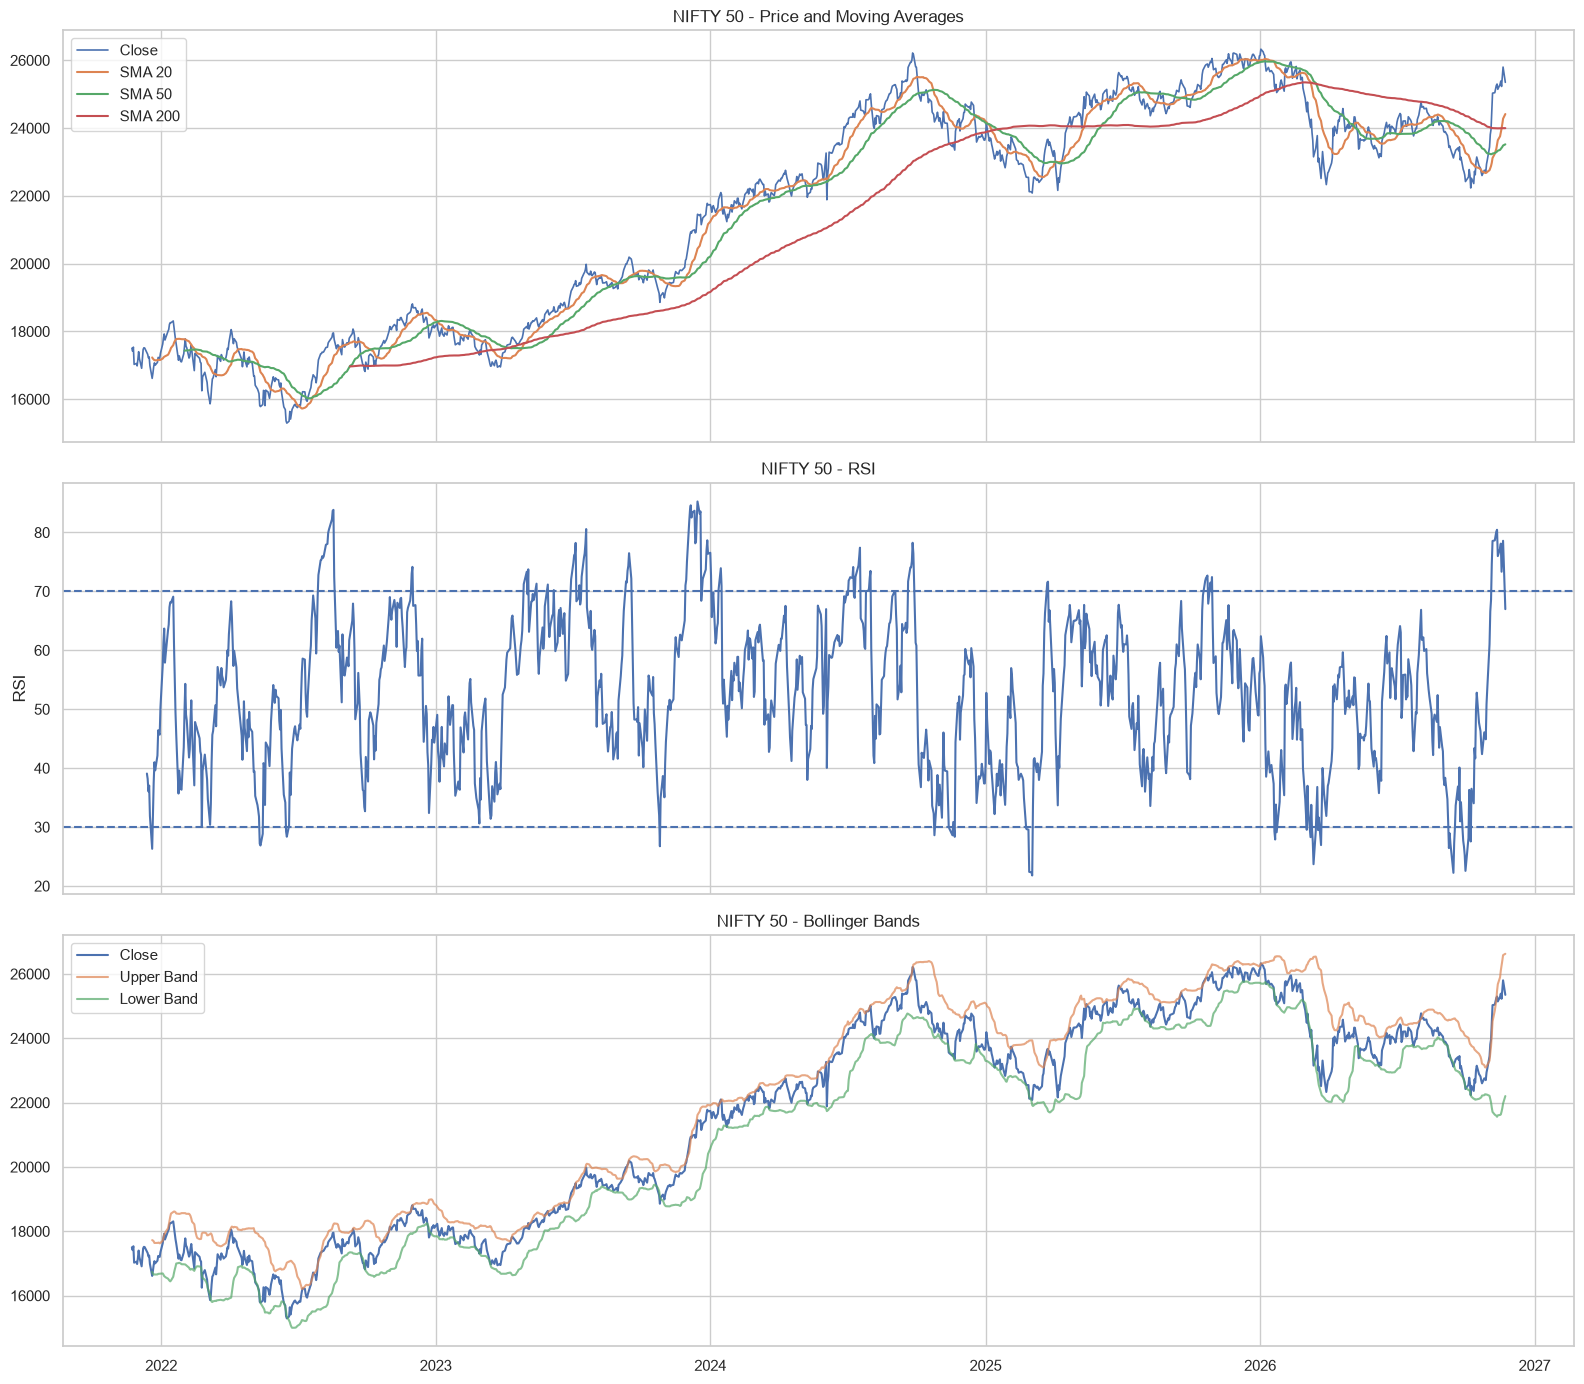

In [18]:
# ============================================
# CELL 18: FEATURE VISUALIZATION
# ============================================

nifty = cleaned_data["NIFTY50"]

fig, axes = plt.subplots(
    3, 1,
    figsize=(16, 14),
    sharex=True
)

# Closing price and moving averages
axes[0].plot(
    nifty["date"],
    nifty["close"],
    label="Close",
    linewidth=1.2
)

axes[0].plot(
    nifty["date"],
    nifty["sma_20"],
    label="SMA 20"
)

axes[0].plot(
    nifty["date"],
    nifty["sma_50"],
    label="SMA 50"
)

axes[0].plot(
    nifty["date"],
    nifty["sma_200"],
    label="SMA 200"
)

axes[0].set_title("NIFTY 50 - Price and Moving Averages")
axes[0].legend()

# RSI
axes[1].plot(
    nifty["date"],
    nifty["rsi_14"],
    label="RSI 14"
)

axes[1].axhline(70, linestyle="--")
axes[1].axhline(30, linestyle="--")

axes[1].set_title("NIFTY 50 - RSI")
axes[1].set_ylabel("RSI")

# Bollinger Bands
axes[2].plot(
    nifty["date"],
    nifty["close"],
    label="Close"
)

axes[2].plot(
    nifty["date"],
    nifty["bb_upper"],
    label="Upper Band",
    alpha=0.7
)

axes[2].plot(
    nifty["date"],
    nifty["bb_lower"],
    label="Lower Band",
    alpha=0.7
)

axes[2].set_title("NIFTY 50 - Bollinger Bands")
axes[2].legend()

plt.tight_layout()

plt.savefig(
    CHART_DIR / "nifty50_engineered_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
# ============================================
# CELL 19: FEATURE SUMMARY
# ============================================

feature_summary = []

for symbol, df in cleaned_data.items():

    feature_summary.append({

        "Symbol": symbol,

        "Rows": len(df),

        "Total Features": len(df.columns),

        "Missing Values": int(df.isna().sum().sum()),

        "RSI Available": df["rsi_14"].notna().sum(),

        "MACD Available": df["macd"].notna().sum(),

        "ATR Available": df["atr_14"].notna().sum(),

        "Target Available": df["target_next_close"].notna().sum()

    })

feature_summary_df = pd.DataFrame(feature_summary)

display(feature_summary_df)

feature_summary_df.to_csv(
    REPORT_DIR / "feature_engineering_summary.csv",
    index=False
)

,Symbol,Rows,Total Features,Missing Values,RSI Available,MACD Available,ATR Available,Target Available
0,NIFTY50,1236,66,925,1222,1211,1223,1235
1,BANKNIFTY,1235,66,925,1221,1210,1222,1234
2,RELIANCE,1237,66,923,1223,1212,1224,1236
3,TCS,1237,66,923,1223,1212,1224,1236
4,HDFCBANK,1237,66,923,1223,1212,1224,1236
5,INFY,1237,66,923,1223,1212,1224,1236
6,ICICIBANK,1237,66,923,1223,1212,1224,1236
7,SBIN,1237,66,923,1223,1212,1224,1236
8,ITC,1237,66,923,1223,1212,1224,1236
9,LT,1237,66,923,1223,1212,1224,1236


In [20]:
# ============================================
# CELL 20: EXPORT FEATURE DATASETS
# ============================================

MODEL_FEATURES = [
    "daily_return",
    "weekly_return",
    "monthly_return",
    "sma_5",
    "sma_10",
    "sma_20",
    "sma_50",
    "sma_100",
    "sma_200",
    "ema_9",
    "ema_12",
    "ema_20",
    "ema_26",
    "ema_50",
    "rsi_14",
    "macd",
    "macd_signal",
    "macd_histogram",
    "bb_width",
    "bb_position",
    "atr_14",
    "atr_percentage",
    "volatility_10",
    "volatility_20",
    "volatility_50",
    "volume_change",
    "volume_ratio",
    "candle_body_percentage",
    "high_low_range_percentage",
    "price_gap_percentage",
    "close_lag_1",
    "close_lag_2",
    "close_lag_3",
    "close_lag_5",
    "close_lag_10",
    "return_lag_1",
    "return_lag_2",
    "return_lag_3",
    "return_lag_5",
    "return_lag_10",
    "year",
    "month",
    "day_of_week",
    "quarter"
]

TARGET_COLUMNS = [
    "target_next_close",
    "target_next_return",
    "target_next_direction"
]

for symbol, df in cleaned_data.items():

    # Save full feature dataset
    full_path = (
        FEATURE_DATA_DIR /
        f"{symbol}_features_full.csv"
    )

    df.to_csv(full_path, index=False)

    # Prepare supervised training dataset
    model_df = df.dropna(
        subset=MODEL_FEATURES + TARGET_COLUMNS
    ).copy()

    model_path = (
        FEATURE_DATA_DIR /
        f"{symbol}_model_ready.csv"
    )

    model_df.to_csv(
        model_path,
        index=False
    )

    print(
        f"{symbol}: {len(model_df)} model-ready records saved"
    )

print("\nFeature datasets exported successfully!")

NIFTY50: 1034 model-ready records saved
BANKNIFTY: 1033 model-ready records saved
RELIANCE: 1037 model-ready records saved
TCS: 1037 model-ready records saved
HDFCBANK: 1037 model-ready records saved
INFY: 1037 model-ready records saved
ICICIBANK: 1037 model-ready records saved
SBIN: 1037 model-ready records saved
ITC: 1037 model-ready records saved
LT: 1037 model-ready records saved

Feature datasets exported successfully!


In [21]:
# ============================================
# CELL 21: FINAL NOTEBOOK STATUS
# ============================================

print("=" * 60)
print("BHARATMARKET AI - FEATURE ENGINEERING REPORT")
print("=" * 60)

print("Total instruments:", len(cleaned_data))

print("Features generated:", len(MODEL_FEATURES))

print("\nGenerated technical indicators:")
print("- SMA")
print("- EMA")
print("- RSI")
print("- MACD")
print("- Bollinger Bands")
print("- ATR")
print("- Rolling volatility")
print("- Volume indicators")
print("- Price action features")
print("- Lag features")
print("- Calendar features")

print("\nForecasting targets:")
print("- Next trading session closing price")
print("- Next trading session return")
print("- Next trading session direction")

print("\nFeature data directory:")
print(FEATURE_DATA_DIR)

print("\nReports directory:")
print(REPORT_DIR)

print("=" * 60)
print("NOTEBOOK 03 COMPLETED")
print("=" * 60)

BHARATMARKET AI - FEATURE ENGINEERING REPORT
Total instruments: 10
Features generated: 44

Generated technical indicators:
- SMA
- EMA
- RSI
- MACD
- Bollinger Bands
- ATR
- Rolling volatility
- Volume indicators
- Price action features
- Lag features
- Calendar features

Forecasting targets:
- Next trading session closing price
- Next trading session return
- Next trading session direction

Feature data directory:
C:\Users\adity\Downloads\Historical data\BharatMarket_AI\data\features

Reports directory:
C:\Users\adity\Downloads\Historical data\BharatMarket_AI\outputs\reports
NOTEBOOK 03 COMPLETED
